# Why do the burden model and the GEA see different context compositions?

Reference TEs are **~16%** of the SV events entering the burden model, but **~27%** of the SVs the GEA
tests (and ~30–36% of its SV hits). Those are the same variants in the same panel, so the gap is made
by the analyses, not by biology. Two things differ, and they act in opposite directions:

**1. The filters.** The burden model requires an event to be **called in ≥ 90% of the 231 founders** and
carried by **≥ 2**; the GEA requires **MAF > 0.05** and applies no call-rate floor. Callability is not
uniform across the genome, so a call-rate filter is also a *context* filter.

**2. The context rule.** The two classifiers disagree on precedence, and on the promoter window:

| | rule |
|---|---|
| burden (`_sv_sfs_context.py`) | CDS > UTR > intron > **TE** > **promoter (≤ 2 kb)** > intergenic |
| GEA (`screen_sig_blocks.classify`) | CDS > UTR > exon(nc) > intron > **promoter (≤ 1 kb)** > **TE** > intergenic > gene desert |

(The GEA's tier *labels* are numbered `3_promoter`, `4_exon_noncoding`, `5_intron`, but that is not the
branch order: `classify` tests the gene body first and only reaches the promoter branch in the `elif`, so a
variant inside a gene body can never be called promoter.)

A variant inside a reference TE *and* upstream of a gene is called **TE** by the burden rule and
**promoter** by the GEA rule. The windows differ too (2 kb vs 1 kb), which moves a further slice.

Note the **sign**: the precedence difference makes the burden's TE share *larger* than the GEA's, but the
burden's TE share is the *smaller* one (16% vs 27%). So the rule difference works against the observed gap
— the call-rate filter accounts for more than the whole of it, not part of it.

Below: the composition at every filter stage, the callability that drives it, and the two rules
measured against each other on the same records.

In [1]:

import os, glob
import numpy as np, pandas as pd, matplotlib as mpl, matplotlib.pyplot as plt
from scipy import stats
plt.rcParams.update({"figure.dpi":120,"font.size":8,"axes.linewidth":0.6,"savefig.bbox":"tight","legend.frameon":False})
G=os.path.abspath(os.path.join(os.getcwd(),"..","r1_sv_negative_selection","results","sv_adaptive")); os.makedirs(f"{G}/plots",exist_ok=True)
# colours: insertions forest green, deletions orange, SNPs grey; dark -> light = coding -> promoter -> intergenic
# (no blue or red: those are the garden-temperature scale)
PAL={"snp_CDS":"0.25","snp_promoter":"0.45","snp_intergenic":"0.65",
     "ins_CDS":"#2F4A1F","ins_promoter":"#4E6B3A","ins_intergenic":"#9DB58C",
     "del_CDS":"#B04A00","del_promoter":"#F07A2E","del_intergenic":"#F8BE91"}; PC=lambda t: PAL[t.split(":")[0]]         # colour of a term (interactions take their term's colour)
def style(a,axis="x"):
    a.set_axisbelow(True); a.grid(color="0.9",lw=0.6,axis=axis)
    for s_ in a.spines.values(): s_.set_visible(False)
def panel(a,letter,x=-0.08,y=1.04): a.annotate(letter,xy=(x,y),xycoords="axes fraction",fontsize=11,fontweight="bold",ha="right")
M="\u2212"
def pct(v,d=3): return f"{v:+.{d}g}%".replace("-",M)
NBPLOTS=os.path.join(os.getcwd(),"plots"); os.makedirs(NBPLOTS,exist_ok=True)          # notebooks/plots/, for the figures kept with the notebook
def save(fig,name,nb=False):
    for d in ([f"{G}/plots"]+([NBPLOTS] if nb else [])):
        fig.savefig(f"{d}/{name}.png",dpi=200,bbox_inches="tight"); fig.savefig(f"{d}/{name}.pdf",bbox_inches="tight")


In [2]:

GS=os.path.abspath(os.path.join(G,"..","..",".."))          # .../analysis/grenenet_selection
E=pd.read_csv(f"{G}/sv_event_catalog.csv"); E["af"]=E.n_carriers/E.n_called.replace(0,np.nan)
CTX=["CDS","UTR","intron","TE","promoter","intergenic"]
CC={"CDS":"#2F4A1F","UTR":"#4E6B3A","intron":"#7E9B6B","TE":"#C46A10","promoter":"#5B7A99","intergenic":"#B9B9B9"}
_c=E.n_called>=0.9*231; _m=E.n_carriers>=2; _f=E.af>0.05; _s=E.origin=="shared"
STAGES=[("no filter\n(every SV event)",np.ones(len(E),bool)),
        ("called in ≥90%\nof 231 founders",_c),
        ("+ ≥2 carriers\n(= the burden pool)",_c&_m),
        ("+ MAF > 0.05\n(the GEA's floor)",_c&_m&_f),
        ("+ shared\n(reported burden model)",_c&_m&_f&_s)]
GEA=pd.read_csv(f"{GS}/genes/convergence/results/gea_hit_landscape.csv.gz")
SV=GEA[GEA.cls=="sv"]
print(f"event catalog {len(E):,} SV events   |   GEA tested SV records {len(SV):,} (MAF ≥ {SV.MAF.min():.3f})")


event catalog 89,940 SV events   |   GEA tested SV records 27,586 (MAF ≥ 0.050)


## 1 · Composition at every filter stage

Each bar is 100% of the events surviving that stage, split by context (burden rule throughout, so only
the filters change). The count on the right is how many events remain.

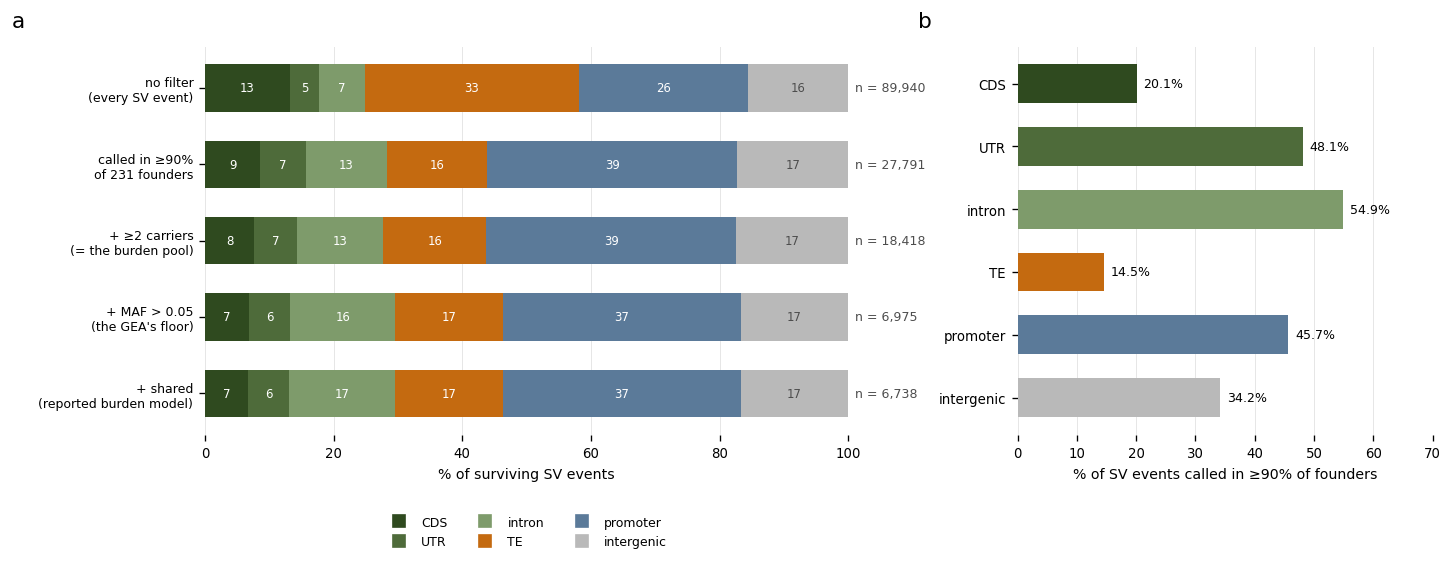

context composition (%) by filter stage, burden context rule:
            no filter (every SV event)  called in ≥90% of 231 founders  + ≥2 carriers (= the burden pool)  + MAF > 0.05 (the GEA's floor)  + shared (reported burden model)
context                                                                                                                                                                    
CDS                               13.2                             8.6                                7.6                             6.8                               6.7
UTR                                4.6                             7.1                                6.7                             6.4                               6.3
intron                             7.1                            12.6                               13.3                            16.3                              16.5
TE                                33.3                            15.6        

In [3]:

fig,ax=plt.subplots(1,2,figsize=(13.2,4.2),gridspec_kw=dict(width_ratios=[1.55,1],wspace=0.32))
a=ax[0]; style(a)
for i,(lab,m) in enumerate(STAGES):
    comp=E[m].context.value_counts(normalize=True).reindex(CTX).fillna(0)*100; left=0
    for c in CTX:
        a.barh(i,comp[c],left=left,height=0.62,color=CC[c],lw=0)
        if comp[c]>=4.5: a.annotate(f"{comp[c]:.0f}",xy=(left+comp[c]/2,i),ha="center",va="center",
                                     fontsize=7,color="white" if c!="intergenic" else "0.3")
        left+=comp[c]
    a.annotate(f"n = {int(m.sum()):,}",xy=(101,i),va="center",fontsize=7.5,color="0.3",annotation_clip=False)
a.set_yticks(range(len(STAGES))); a.set_yticklabels([s for s,_ in STAGES],fontsize=7.5); a.invert_yaxis()
a.set_xlim(0,100); a.set_xlabel("% of surviving SV events",fontsize=8.5)
a.annotate("a",xy=(-0.30,1.05),xycoords="axes fraction",fontsize=13)
h_=[a.barh([],[],color=CC[c])[0] if False else a.plot([],[],"s",color=CC[c],ms=7)[0] for c in CTX]
a.legend(h_,CTX,frameon=False,fontsize=7.5,ncol=3,loc="upper center",bbox_to_anchor=(0.5,-0.18))
a=ax[1]; style(a)
cr=(E.assign(_ok=(E.n_called>=0.9*231)).groupby("context")._ok.mean()*100).reindex(CTX)
for i,c in enumerate(CTX):
    a.barh(i,cr[c],height=0.62,color=CC[c],lw=0)
    a.annotate(f"{cr[c]:.1f}%",xy=(cr[c],i),xytext=(4,0),textcoords="offset points",va="center",fontsize=7.5)
a.set_yticks(range(len(CTX))); a.set_yticklabels(CTX,fontsize=8); a.invert_yaxis(); a.set_xlim(0,70)
a.set_xlabel("% of SV events called in ≥90% of founders",fontsize=8.5)
a.annotate("b",xy=(-0.24,1.05),xycoords="axes fraction",fontsize=13)
save(fig,"sv_context_cascade",nb=True); plt.show()
T=pd.DataFrame({lab.replace(chr(10)," "):(E[m].context.value_counts(normalize=True).reindex(CTX)*100).round(1)
                for lab,m in STAGES})
T.loc["n events"]=[int(m.sum()) for _,m in STAGES]
print("context composition (%) by filter stage, burden context rule:"); print(T.to_string())
print("\ncall rate by context — share of events called in ≥90% of the 231 founders:")
print(cr.round(1).to_string())


## 2 · The context rule, measured on the same records

The GEA table carries **both** promoter windows on every tested record, so the window effect can be read
off directly: widening the promoter from 1 kb to 2 kb moves variants out of TE and intergenic and into
promoter, with no change of data or filter. The precedence difference acts the same way — the burden rule
resolves a TE∩promoter variant to TE, the GEA rule to promoter.

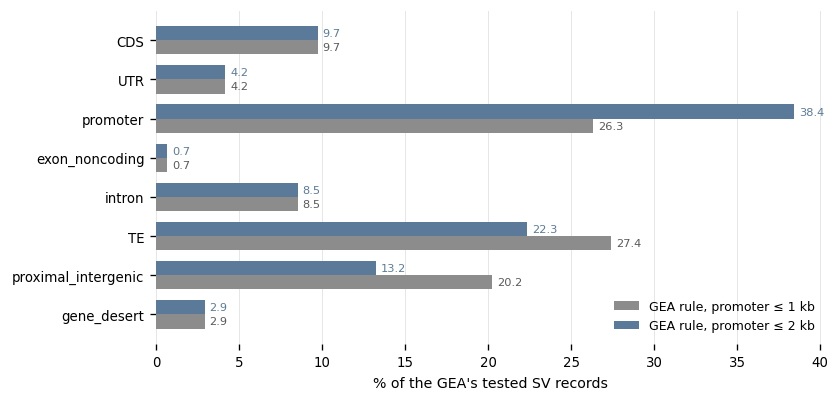

GEA tested SVs under its own rule, two promoter windows (%):
                       promoter ≤1 kb  promoter ≤2 kb  shift
1_CDS                             9.7             9.7    0.0
2_UTR                             4.2             4.2    0.0
3_promoter                       26.3            38.4   12.1
4_exon_noncoding                  0.7             0.7    0.0
5_intron                          8.5             8.5    0.0
6_TE                             27.4            22.3   -5.1
7_proximal_intergenic            20.2            13.2   -7.0
8_gene_desert                     2.9             2.9    0.0


In [4]:

fig,a=plt.subplots(figsize=(7.2,3.6)); style(a)
TIER=["1_CDS","2_UTR","3_promoter","4_exon_noncoding","5_intron","6_TE","7_proximal_intergenic","8_gene_desert"]
t1=SV.tier_1kb.value_counts(normalize=True).reindex(TIER).fillna(0)*100
t2=SV.tier_2kb.value_counts(normalize=True).reindex(TIER).fillna(0)*100
y=np.arange(len(TIER)); h=0.36
a.barh(y+h/2,t1,height=h,color="0.55",lw=0,label="GEA rule, promoter ≤ 1 kb")
a.barh(y-h/2,t2,height=h,color="#5B7A99",lw=0,label="GEA rule, promoter ≤ 2 kb")
for yy,v in zip(y+h/2,t1): a.annotate(f"{v:.1f}",xy=(v,yy),xytext=(3,0),textcoords="offset points",va="center",fontsize=6.8,color="0.35")
for yy,v in zip(y-h/2,t2): a.annotate(f"{v:.1f}",xy=(v,yy),xytext=(3,0),textcoords="offset points",va="center",fontsize=6.8,color="#5B7A99")
a.set_yticks(y); a.set_yticklabels([t.split("_",1)[1] for t in TIER],fontsize=8); a.invert_yaxis()
a.set_xlabel("% of the GEA's tested SV records",fontsize=8.5); a.legend(frameon=False,fontsize=7.5,loc="lower right")
save(fig,"sv_context_rule",nb=True); plt.show()
print("GEA tested SVs under its own rule, two promoter windows (%):")
print(pd.DataFrame({"promoter ≤1 kb":t1.round(1),"promoter ≤2 kb":t2.round(1),"shift":(t2-t1).round(1)}).to_string())


## 3 · The whole transition, one thing at a time

Sections 1 and 2 vary the filters and the rule separately but on different starting sets, so the two
cannot be added up. Here both tracks start from the **same** bar — every SV record in the panel under
the burden rule — and each step changes exactly one thing, so the composition can be followed all the
way to each reported figure.

**Arm A** is the burden track: record → event (unit), then its filters. The italic tag beside
each `n` names the single thing that step changed.
**Arm B** is the GEA track: the same records under the GEA's frequency filter (no call-rate floor), then
its rule, then its promoter window.

`exon(nc)` exists only under the GEA rule. The burden rule has no branch for it — a non-coding exon is
neither CDS nor UTR, and `gene & ~exon` excludes it from intron — so those variants fall through to
TE / promoter / intergenic there. It is 0.7% of records, so it changes nothing, but it is why the two
rules cannot be made to agree by relabelling alone.

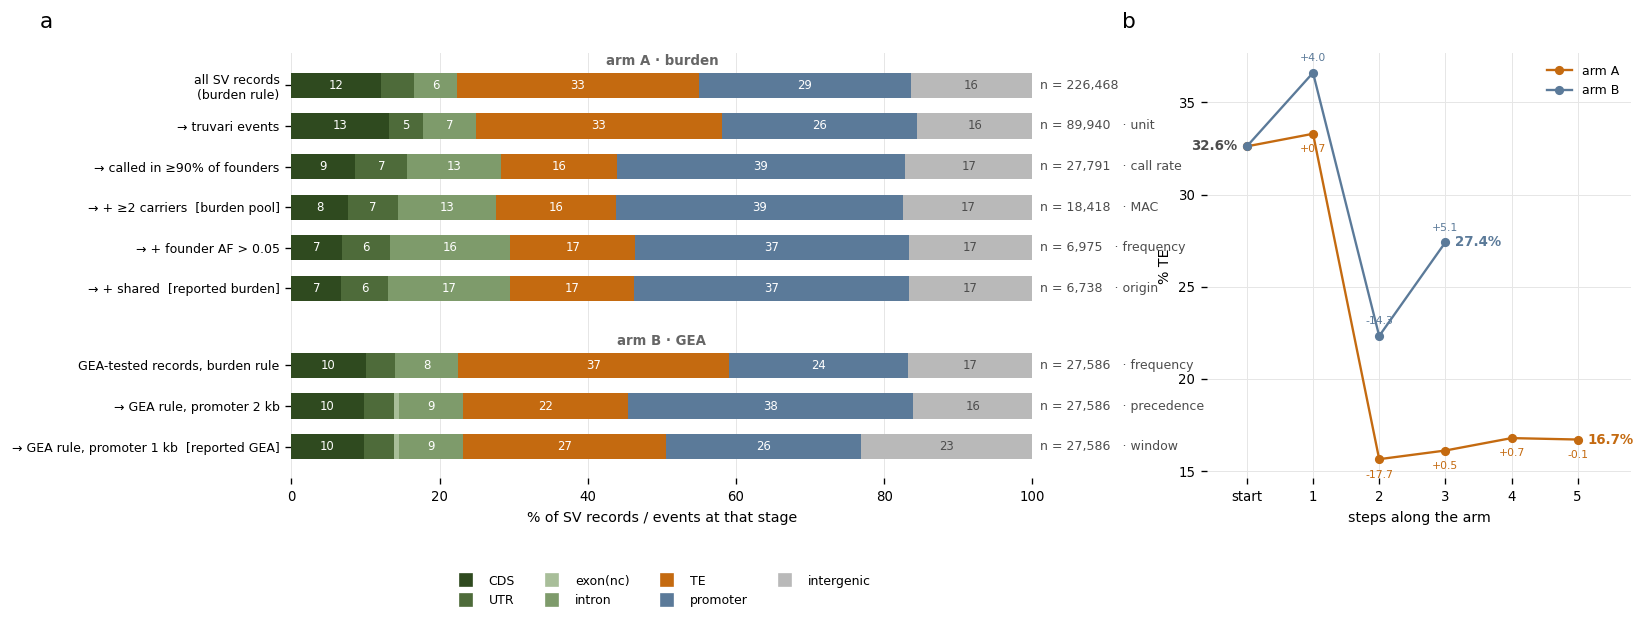

full transition, burden rule unless the row says otherwise (%):
                                            CDS  UTR  exon(nc)  intron    TE  promoter  intergenic       n
all SV records (burden rule)               12.1  4.4       0.0     5.9  32.6      28.6        16.4  226468
→ truvari events                           13.2  4.6       0.0     7.1  33.3      26.3        15.6   89940
→ called in ≥90% of founders                8.6  7.1       0.0    12.6  15.6      38.9        17.2   27791
→ + ≥2 carriers  [burden pool]              7.6  6.7       0.0    13.3  16.1      38.8        17.5   18418
→ + founder AF > 0.05                       6.8  6.4       0.0    16.3  16.8      36.9        16.7    6975
→ + shared  [reported burden]               6.7  6.3       0.0    16.5  16.7      37.0        16.7    6738
GEA-tested records, burden rule            10.0  4.0       0.0     8.5  36.6      24.1        16.8   27586
→ GEA rule, promoter 2 kb                   9.7  4.2       0.7     8.5  22.3    

In [5]:

PN=pd.read_csv(f"{G}/sv_context_decomposition_panel.csv.gz")
GD=pd.read_csv(f"{G}/sv_context_decomposition_gea.csv.gz")
CTX2=["CDS","UTR","exon(nc)","intron","TE","promoter","intergenic"]
CC2=dict(CC); CC2["exon(nc)"]="#A8BE99"
TMAP={"1_CDS":"CDS","2_UTR":"UTR","3_promoter":"promoter","4_exon_noncoding":"exon(nc)",
      "5_intron":"intron","6_TE":"TE","7_proximal_intergenic":"intergenic","8_gene_desert":"intergenic"}
cmp_=lambda s:(s.value_counts(normalize=True).reindex(CTX2).fillna(0)*100)
EVC=PN.groupby("event").context.first()                      # event context = first record, as _sv_event_catalog.py
ARM=[("A","all SV records\n(burden rule)",cmp_(PN.context),len(PN),None),
     ("A","→ truvari events",cmp_(EVC),EVC.size,"unit"),
     ("A","→ called in ≥90% of founders",cmp_(E[_c].context),int(_c.sum()),"call rate"),
     ("A","→ + ≥2 carriers  [burden pool]",cmp_(E[_c&_m].context),int((_c&_m).sum()),"MAC"),
     ("A","→ + founder AF > 0.05",cmp_(E[_c&_m&_f].context),int((_c&_m&_f).sum()),"frequency"),
     ("A","→ + shared  [reported burden]",cmp_(E[_c&_m&_f&_s].context),int((_c&_m&_f&_s).sum()),"origin"),
     ("B","GEA-tested records, burden rule",cmp_(GD.context),len(GD),"frequency"),
     ("B","→ GEA rule, promoter 2 kb",cmp_(GD.tier_2kb.map(TMAP)),len(GD),"precedence"),
     ("B","→ GEA rule, promoter 1 kb  [reported GEA]",cmp_(GD.tier_1kb.map(TMAP)),len(GD),"window")]
YS=[0,1,2,3,4,5,6.9,7.9,8.9]                                  # gap between the arms
fig,ax=plt.subplots(1,2,figsize=(14.4,4.6),gridspec_kw=dict(width_ratios=[1.75,1],wspace=0.30))
a=ax[0]; style(a)
for (arm,lab,c,n,ch),yy in zip(ARM,YS):
    left=0
    for k in CTX2:
        a.barh(yy,c[k],left=left,height=0.62,color=CC2[k],lw=0)
        if c[k]>=4.5: a.annotate(f"{c[k]:.0f}",xy=(left+c[k]/2,yy),ha="center",va="center",fontsize=7,
                                 color="white" if k not in("intergenic","exon(nc)") else "0.3")
        left+=c[k]
    a.annotate(f"n = {n:,}" + (f"   · {ch}" if ch else ""),xy=(101,yy),va="center",
               fontsize=7.5,color="0.3",annotation_clip=False)
a.set_yticks(YS); a.set_yticklabels([l for _,l,_,_,_ in ARM],fontsize=7.5); a.invert_yaxis()
a.set_xlim(0,100); a.set_xlabel("% of SV records / events at that stage",fontsize=8.5)
a.annotate("arm A · burden",xy=(0.5,-0.5),xycoords=("axes fraction","data"),fontsize=8,
           color="0.4",ha="center",fontweight="bold")
a.annotate("arm B · GEA",xy=(0.5,6.4),xycoords=("axes fraction","data"),fontsize=8,
           color="0.4",ha="center",fontweight="bold")
a.annotate("a",xy=(-0.34,1.06),xycoords="axes fraction",fontsize=13)
a.legend([a.plot([],[],"s",color=CC2[k],ms=7)[0] for k in CTX2],CTX2,frameon=False,fontsize=7.5,
         ncol=4,loc="upper center",bbox_to_anchor=(0.5,-0.20))
# b: the TE share, followed step by step down each arm from the shared start
a=ax[1]; style(a,axis="both")
for arm,col in (("A","#C46A10"),("B","#5B7A99")):
    idx=[0]+[i for i,r in enumerate(ARM) if r[0]==arm and i>0]
    xs=list(range(len(idx))); ys=[ARM[i][2]["TE"] for i in idx]
    a.plot(xs,ys,"-o",color=col,ms=4.5,lw=1.4,label=f"arm {arm}")
    for j,(x,y) in enumerate(zip(xs,ys)):
        if j: a.annotate(f"{y-ys[j-1]:+.1f}",xy=(x,y),xytext=(0,-11 if arm=="A" else 7),
                         textcoords="offset points",ha="center",fontsize=6.5,color=col)
    a.annotate(f"{ys[-1]:.1f}%",xy=(xs[-1],ys[-1]),xytext=(6,0),textcoords="offset points",
               va="center",fontsize=8,color=col,fontweight="bold")
a.annotate(f"{ARM[0][2]['TE']:.1f}%",xy=(0,ARM[0][2]["TE"]),xytext=(-6,0),textcoords="offset points",
           ha="right",va="center",fontsize=8,color="0.3",fontweight="bold")
a.set_xticks(range(6)); a.set_xticklabels(["start","1","2","3","4","5"],fontsize=8)
a.set_xlabel("steps along the arm",fontsize=8.5); a.set_ylabel("% TE",fontsize=8.5)
a.set_xlim(-0.6,5.8); a.legend(frameon=False,fontsize=7.5,loc="upper right")
a.annotate("b",xy=(-0.20,1.06),xycoords="axes fraction",fontsize=13)
save(fig,"sv_context_full_transition",nb=True); plt.show()
FT=pd.DataFrame({l.replace(chr(10)," "):c.round(1) for _,l,c,_,_ in ARM}).T
FT["n"]=[n for _,_,_,n,_ in ARM]
print("full transition, burden rule unless the row says otherwise (%):"); print(FT.to_string())
print("\nTE step by step:")
for arm in ("A","B"):
    idx=[0]+[i for i,r in enumerate(ARM) if r[0]==arm and i>0]; prev=None
    print(f"  arm {arm}:")
    for i in idx:
        t=ARM[i][2]["TE"]; d="" if prev is None else f"{t-prev:+6.1f}"
        print(f"    {t:5.1f}%{d:>8}   {ARM[i][1]}"); prev=t


## 4 · Reading it

**The call-rate filter is the dominant term, and it is a context filter in disguise.** Reference TEs are
**33.3%** of all SV events but **15.6%** after requiring calls in ≥ 90% of founders — because only
**14.5%** of TE events clear that bar, the lowest of any context by a wide margin (intron 54.9%, UTR
48.1%, promoter 45.7%, intergenic 34.2%, CDS 20.1%). Repetitive sequence is where the pangenome
genotypes worst, so a call-rate floor removes TEs preferentially. The GEA applies **no call-rate floor**,
so it keeps them.

The later filters barely move composition: MAC and MAF cost events roughly evenly across contexts, and
the `shared` filter changes composition by well under a percentage point.

**The context rule then moves a second slice, in the opposite direction.** On the GEA's own tested SVs,
widening the promoter window from 1 kb to 2 kb takes TE from 27.4% to 22.3% and promoter from 26.3% to
38.4% — the same records, reclassified. The burden rule uses the 2 kb window *and* ranks TE above
promoter, which pushes back the other way. So the two rules are not a small annotation difference: they
disagree about roughly a sixth of all tested SVs.

**What this means for reading the two figures together.** A "TE" bar in the GEA hit landscape and a "TE"
bar in the burden counts are not the same category counted two ways — they are different categories over
different variant sets. The GEA's TE share is high partly because it retains variants the burden model
cannot genotype confidently; the burden's promoter share is high partly because its rule claims variants
the GEA calls TE.

⚠ **Neither is wrong, but they are not comparable as drawn.** If the two need to be shown side by side,
they should be put on one context rule and one filter set first. Nothing here says which rule is better:
the burden model's call-rate floor exists because a per-founder burden needs reliable per-founder
genotypes, and the GEA's lack of one exists because it tests frequencies in pools, not founder genotypes.
Both are defensible for their own question.

## As run

- **Burden side:** `results/sv_adaptive/sv_event_catalog.csv` — truvari-collapsed SV events with the
  burden context rule (`_sv_sfs_context.CTX`), `n_called`, `n_carriers`, `origin`. AF is
  `n_carriers / n_called`, so the "MAF > 0.05" stage is that ratio, not the pool frequency the GEA uses;
  it is included to show the filter's *size*, not to reproduce the GEA exactly.
- **GEA side:** `genes/convergence/results/gea_hit_landscape.csv.gz` — every record the GEA tested
  (676,203 small indels + 27,586 SVs, MAF > 0.05 already applied), carrying `tier_1kb` and `tier_2kb`
  from `annotate_gea_universe.py`, which reuses `screen_sig_blocks.classify`.
- Unit differs between the two tracks (events vs records): the 226,468 SV records of the arch3 panel
  (`|alt_len - ref_len| > 50`) are truvari-collapsed to the 89,940 events here — all of them, the
  `n_carriers >= 1` filter in `_sv_event_catalog.py` drops nothing. **Measured, this is not a third term.**
  The collapse ratio is nearly flat across contexts (intron 2.08, CDS 2.31, UTR 2.43, TE 2.47,
  intergenic 2.66, promoter 2.74 alleles/event), so the TE share is 33.3% of events and 32.7% of records
  — a 0.6-point move, in the *opposite* direction to the one an allele-splitting bias would predict.
  With the unit term ruled out and the rule difference pushing the wrong way, the call-rate filter is
  effectively the whole of the gap.